In [34]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# Clinical information
cases = pd.read_csv("https://api.vitaldb.net/cases")

# Track list
trks = pd.read_csv("https://api.vitaldb.net/trks")

# Laboratory results
labs = pd.read_csv("https://api.vitaldb.net/labs")

In [5]:
print(cases.shape, trks.shape, labs.shape)

(6388, 74) (486449, 3) (928448, 4)


In [6]:
cases.head()

,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1,5955,0,11542,-552,10848.0,1668,10368,-236220,627780,...,0,120,0.0,100,70,0,10,0,0,0
1,2,2487,0,15741,-1039,14921.0,1721,14621,-221160,1506840,...,0,150,0.0,0,100,0,20,0,0,0
2,3,2861,0,4394,-590,4210.0,1090,3010,-218640,40560,...,0,0,0.0,0,50,0,0,0,0,0
3,4,1903,0,20990,-778,20222.0,2522,17822,-201120,576480,...,0,80,0.0,100,100,0,50,0,0,0
4,5,4416,0,21531,-1009,22391.0,2591,20291,-67560,3734040,...,0,0,0.0,0,160,0,10,900,0,2100


In [12]:
cases.columns

Index(['caseid', 'subjectid', 'casestart', 'caseend', 'anestart', 'aneend',
       'opstart', 'opend', 'adm', 'dis', 'icu_days', 'death_inhosp', 'age',
       'sex', 'height', 'weight', 'bmi', 'asa', 'emop', 'department', 'optype',
       'dx', 'opname', 'approach', 'position', 'ane_type', 'preop_htn',
       'preop_dm', 'preop_ecg', 'preop_pft', 'preop_hb', 'preop_plt',
       'preop_pt', 'preop_aptt', 'preop_na', 'preop_k', 'preop_gluc',
       'preop_alb', 'preop_ast', 'preop_alt', 'preop_bun', 'preop_cr',
       'preop_ph', 'preop_hco3', 'preop_be', 'preop_pao2', 'preop_paco2',
       'preop_sao2', 'cormack', 'airway', 'tubesize', 'dltubesize', 'lmasize',
       'iv1', 'iv2', 'aline1', 'aline2', 'cline1', 'cline2', 'intraop_ebl',
       'intraop_uo', 'intraop_rbc', 'intraop_ffp', 'intraop_crystalloid',
       'intraop_colloid', 'intraop_ppf', 'intraop_mdz', 'intraop_ftn',
       'intraop_rocu', 'intraop_vecu', 'intraop_eph', 'intraop_phe',
       'intraop_epi', 'intraop_ca'],
     

In [36]:
for i in cases.columns:
    print(i, cases[i].dtype)

caseid int64
subjectid int64
casestart int64
caseend int64
anestart int64
aneend float64
opstart int64
opend int64
adm int64
dis int64
icu_days int64
death_inhosp int64
age float64
sex str
height float64
weight float64
bmi float64
asa float64
emop int64
department str
optype str
dx str
opname str
approach str
position str
ane_type str
preop_htn int64
preop_dm int64
preop_ecg str
preop_pft str
preop_hb float64
preop_plt float64
preop_pt float64
preop_aptt float64
preop_na float64
preop_k float64
preop_gluc float64
preop_alb float64
preop_ast float64
preop_alt float64
preop_bun float64
preop_cr float64
preop_ph float64
preop_hco3 float64
preop_be float64
preop_pao2 float64
preop_paco2 float64
preop_sao2 float64
cormack str
airway str
tubesize float64
dltubesize str
lmasize float64
iv1 str
iv2 str
aline1 str
aline2 str
cline1 str
cline2 str
intraop_ebl float64
intraop_uo float64
intraop_rbc int64
intraop_ffp int64
intraop_crystalloid float64
intraop_colloid int64
intraop_ppf int64
intraop

In [ ]:
# Type d'intervention
cases["optype"].value_counts()

optype
Colorectal          1350
Biliary/Pancreas     812
Others               799
Stomach              676
Major resection      584
Minor resection      553
Breast               434
Transplantation      403
Vascular             262
Hepatic              258
Thyroid              257
Name: count, dtype: int64

In [ ]:
# Type d'anesthésie
cases["ane_type"].value_counts()


ane_type
General            6043
Spinal              273
Sedationalgesia      72
Name: count, dtype: int64

In [ ]:
cases["age"].describe()

count    6388.000000
mean       57.296493
std        14.976461
min         0.300000
25%        48.000000
50%        59.000000
75%        68.000000
max        94.000000
Name: age, dtype: float64

In [25]:
print("Chirurgies :", cases["caseid"].nunique())
print("Patients   :", cases["subjectid"].nunique())
cases["subjectid"].value_counts().head()

Chirurgies : 6388
Patients   : 6090


subjectid
3131    14
1609    10
4306     8
2291     6
10       5
Name: count, dtype: int64

Plusieurs chirurgies pour un patient

In [29]:
# Durée d'anesthésie
duration = (cases["aneend"] - cases["anestart"]) / 60
duration.describe()

count    6.388000e+03
mean    -9.431647e+03
std      7.697804e+05
min     -6.152447e+07
25%      1.120000e+02
50%      1.750000e+02
75%      2.600000e+02
max      1.860000e+03
dtype: float64

In [ ]:
# Le cas aberrant
cases.loc[duration < 0, ["caseid", "anestart", "aneend", "casestart", "caseend"]]

,caseid,anestart,aneend,casestart,caseend
4475,4476,-2156,-3.691470e+09,0,19501


In [31]:
# PA invasive
art_ids = set(trks.loc[trks["tname"] == "SNUADC/ART", "caseid"])
mbp_ids = set(trks.loc[trks["tname"] == "Solar8000/ART_MBP", "caseid"])
print("SNUADC/ART        :", len(art_ids))
print("Solar8000/ART_MBP :", len(mbp_ids))
print("Les deux          :", len(art_ids & mbp_ids))

SNUADC/ART        : 3645
Solar8000/ART_MBP : 3724
Les deux          : 3644


In [32]:
# Echantillonnage brut de la PAM
tid = trks.loc[(trks["caseid"] == 1) & (trks["tname"] == "Solar8000/ART_MBP"), "tid"].iloc[0]
mbp = pd.read_csv(f"https://api.vitaldb.net/{tid}")
mbp.head(20)

,Time,Solar8000/ART_MBP
0,1.818,-8
1,3.817,-8
2,5.818,-8
3,7.817,-9
4,9.817,-9
5,11.816,-8
6,13.816,-8
7,15.815,-9
8,17.815,-9
9,19.814,-9


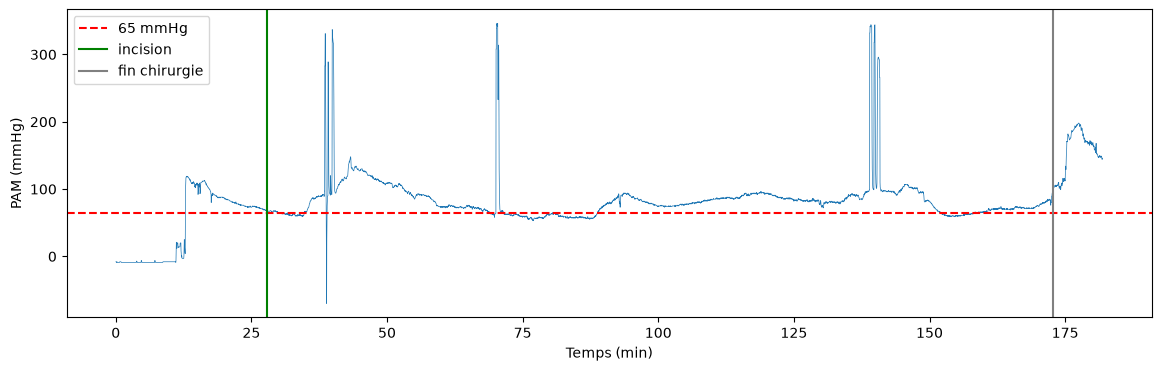

In [ ]:
case = cases.loc[cases["caseid"] == 1].iloc[0]

plt.figure(figsize=(14, 4))
plt.plot(mbp["Time"] / 60, mbp["Solar8000/ART_MBP"], lw=0.5)
plt.axhline(65, color="red", ls="--", label="65 mmHg")
plt.axvline(case["opstart"] / 60, color="green", label="incision")
plt.axvline(case["opend"] / 60, color="gray", label="fin chirurgie")
plt.xlabel("Temps (min)")
plt.ylabel("PAM (mmHg)")
plt.legend()
plt.show()

## Liste de features, présente durant la chirurgie
"age", "weight", "bmi", "asa","preop_hb", "preop_alb", "preop_cr", "preop_na", "emop", "preop_htn", "preop_dm", "sex", "department", "optype", "approach", "position"

Les autres features sont hors chirurgie

In [7]:
trks.head()

,caseid,tname,tid
0,1,BIS/BIS,fd869e25ba82a66cc95b38ed47110bf4f14bb368
1,1,BIS/EEG1_WAV,0aa685df768489a18a5e9f53af0d83bf60890c73
2,1,BIS/EEG2_WAV,ad13b2c39b19193c8ae4a2de4f8315f18d61a57e
3,1,BIS/EMG,2525603efe18d982764dbca457affe7a45e766a9
4,1,BIS/SEF,1c91aec859304840dec75acf4a35da78be0e8ef0


In [ ]:
# Liste des signaux enregistrés pour une chirurgie
trks[trks["caseid"] == 1]

,caseid,tname,tid
0,1,BIS/BIS,fd869e25ba82a66cc95b38ed47110bf4f14bb368
1,1,BIS/EEG1_WAV,0aa685df768489a18a5e9f53af0d83bf60890c73
2,1,BIS/EEG2_WAV,ad13b2c39b19193c8ae4a2de4f8315f18d61a57e
3,1,BIS/EMG,2525603efe18d982764dbca457affe7a45e766a9
4,1,BIS/SEF,1c91aec859304840dec75acf4a35da78be0e8ef0
...,...,...,...
71,1,Solar8000/VENT_PPLAT,e1e55590c9da90de55892edf941247b7a6d9213c
72,1,Solar8000/VENT_RR,0b0b820e617889fcc464525f0698fdfc2b3fa79e
73,1,Solar8000/VENT_SET_PCP,e32742aa29d8e4ded02093617f05c1ca72bad344
74,1,Solar8000/VENT_SET_TV,8049dc651b8a55b1c5f0ab17a2e72c1f188b2596


In [ ]:
# Signaux les plus fréquents
trks["tname"].value_counts().head(30)

tname
Solar8000/HR             6387
Solar8000/PLETH_HR       6386
Solar8000/PLETH_SPO2     6386
Primus/CO2               6362
Primus/PAMB_MBAR         6361
Primus/SET_AGE           6361
Primus/AWP               6360
SNUADC/ECG_II            6355
Primus/VENT_LEAK         6344
Primus/ETCO2             6339
Primus/FEN2O             6339
Primus/FIN2O             6339
Primus/INCO2             6339
Primus/MAC               6338
Primus/MAWP_MBAR         6338
Primus/FEO2              6335
Primus/FIO2              6335
Primus/RR_CO2            6328
Solar8000/VENT_MAWP      6299
Solar8000/ETCO2          6242
Solar8000/INCO2          6242
Solar8000/FEO2           6239
Solar8000/FIO2           6239
Solar8000/RR_CO2         6177
SNUADC/PLETH             6157
Primus/SET_FIO2          6047
Primus/SET_FRESH_FLOW    6042
Primus/MV                6022
Primus/TV                6018
Primus/COMPLIANCE        6017
Name: count, dtype: int64

In [8]:
labs.head()

,caseid,dt,name,result
0,1,594470,alb,2.9
1,1,399575,alb,3.2
2,1,12614,alb,3.4
3,1,137855,alb,3.6
4,1,399575,alt,12.0
